# importar lo necesario


In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

p = print
d = display

### creación de la carpeta de fotos

In [2]:
Carpeta_Proyecto = Path.cwd().parent
Carpeta_fotos = Carpeta_Proyecto/"Dataset"/"Fotos"
Carpeta_fotos.mkdir(parents=True, exist_ok=True)
p(Carpeta_fotos)

/home/Ian/prediccion_red/Dataset/Fotos


### abrir la foto

In [3]:
ruta_foto = Carpeta_fotos/"01_fot.jpeg"
foto = cv2.imread(str(ruta_foto))
p("Tamaño original:", foto.shape)

Tamaño original: (1600, 1204, 3)


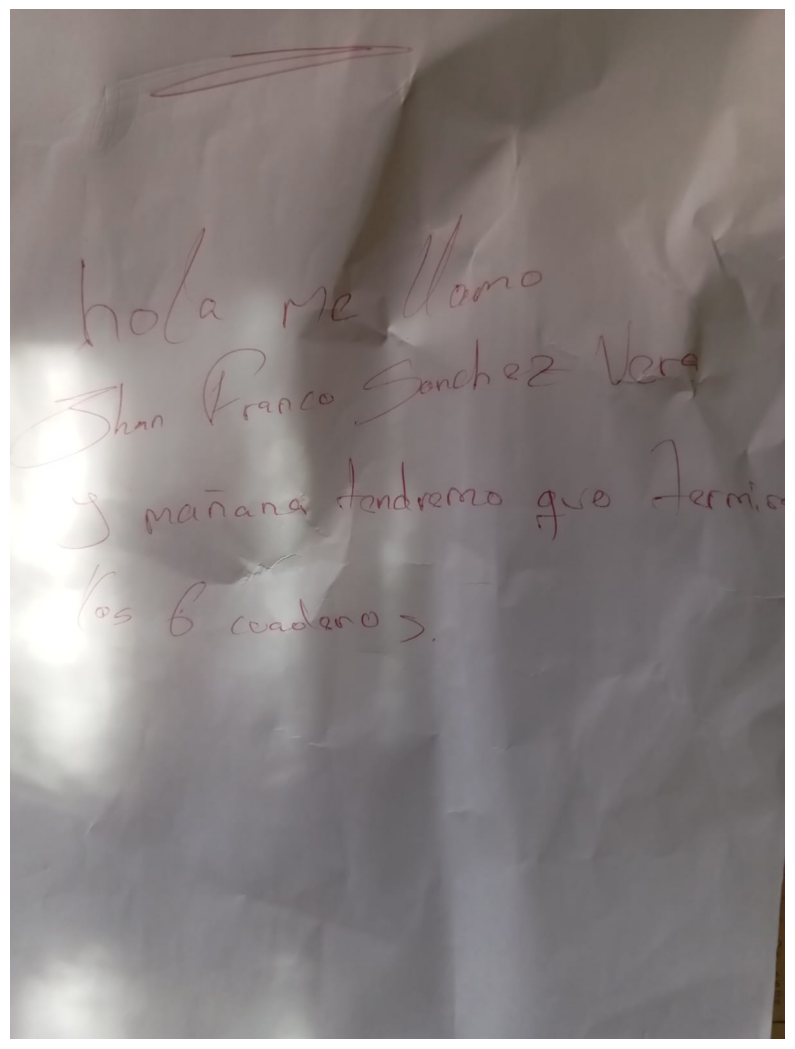

In [4]:
plt.figure(figsize=(10, 18))
plt.imshow(cv2.cvtColor(foto, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

### escalar la foto

In [5]:
alto, ancho = foto.shape[:2]
nuevo_ancho = 1200
nuevo_alto = int(alto * nuevo_ancho / ancho)

foto_scala = cv2.resize(foto, (nuevo_ancho, nuevo_alto), interpolation=cv2.INTER_AREA)
p("Tamaño nuevo:", foto_scala.shape)

Tamaño nuevo: (1594, 1200, 3)


### foto a gris

Tamaño en gris: (1594, 1200)


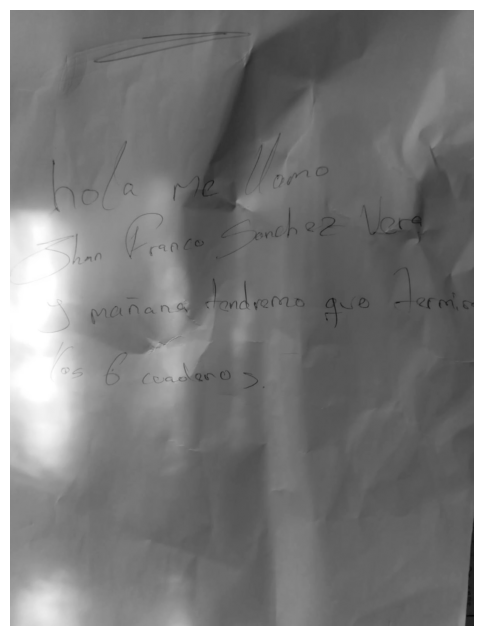

In [6]:
gris = cv2.cvtColor(foto_scala, cv2.COLOR_BGR2GRAY)
p("Tamaño en gris:", gris.shape)

plt.figure(figsize=(6, 8))
plt.imshow(gris, cmap="gray")
plt.axis("off")
plt.show()

### emparejar o eliminar la luz

In [7]:
nucleo = np.ones((15, 15), np.uint8)
fondo = cv2.medianBlur(cv2.dilate(gris, nucleo), 31)


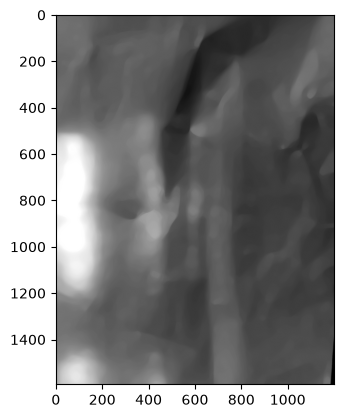

In [8]:
plt.imshow(fondo, cmap="gray")
plt.show()

In [9]:
gris_parejo = cv2.divide(gris, fondo, scale=255)


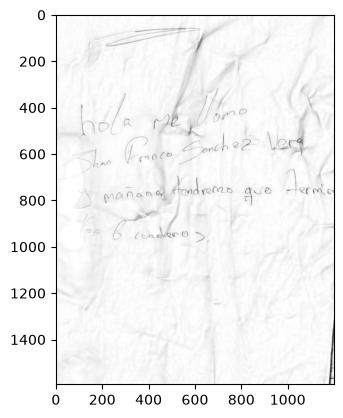

In [10]:
plt.imshow(gris_parejo, cmap="gray")
plt.show()

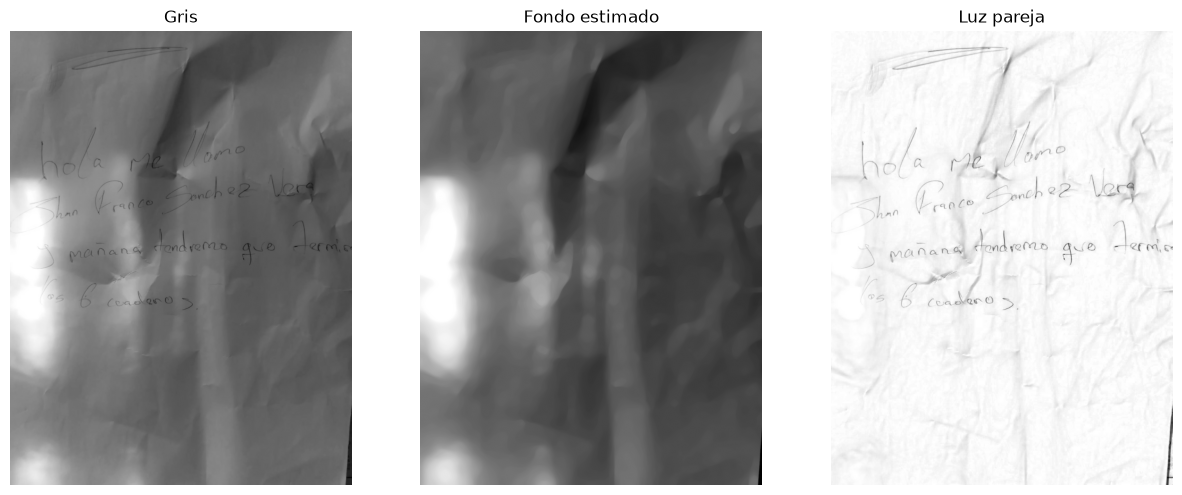

In [11]:
plt.figure(figsize=(15, 6))
for i, (imagen, titulo) in enumerate([(gris, "Gris"), (fondo, "Fondo estimado"), (gris_parejo, "Luz pareja")]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(imagen, cmap="gray")
    plt.title(titulo)
    plt.axis("off")
plt.show()

### separar las letras de la hoja con K-Means

In [12]:
from sklearn.cluster import KMeans

puntos = gris_parejo.reshape(-1, 1).astype(np.float32)
p("Forma de puntos:", puntos.shape)

Forma de puntos: (1912800, 1)


### se escogen 20 000 píxeles al azar

In [31]:
generador = np.random.default_rng(42)
muestra = puntos[generador.choice(len(puntos), 20000, replace=False)]
p("Tamaño de la muestra:", muestra.shape)

Tamaño de la muestra: (20000, 1)


### separar los píxeles de la muestra en dos grupos con K-Means

In [14]:
km = KMeans(n_clusters=2, random_state=42, n_init=10)
km.fit(muestra)
p("Centros:", km.cluster_centers_)

Centros: [[248.72069]
 [195.16847]]


In [15]:
grupos = km.predict(puntos)
p("Forma de grupos:", grupos.shape)
p("Puntos por grupo:", pd.Series(grupos).value_counts().to_dict())

Forma de grupos: (1912800,)
Puntos por grupo: {0: 1870054, 1: 42746}


### comparar el porcentaje de tinta en la muestra de 20 000 píxeles y en toda la foto

In [16]:
p("Tinta en la muestra:", round((km.predict(muestra) == 1).mean() * 100, 2), "%")
p("Tinta en toda la foto:", round((grupos == 1).mean() * 100, 2), "%")

Tinta en la muestra: 2.32 %
Tinta en toda la foto: 2.23 %


### identificar con los centros de K-Means cuál de los dos grupos es la tinta

In [17]:
centros = km.cluster_centers_.ravel()
gr_tinta= np.argmin(centros)
p("Centros: ", centros)
p("el grupo de centros o (tinta) es: ", gr_tinta)

Centros:  [248.72069 195.16847]
el grupo de centros o (tinta) es:  1


### armar la imagen con los píxeles de la tinta

In [18]:
grupos_imagen = grupos.reshape(gris_parejo.shape)
p(grupos_imagen)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


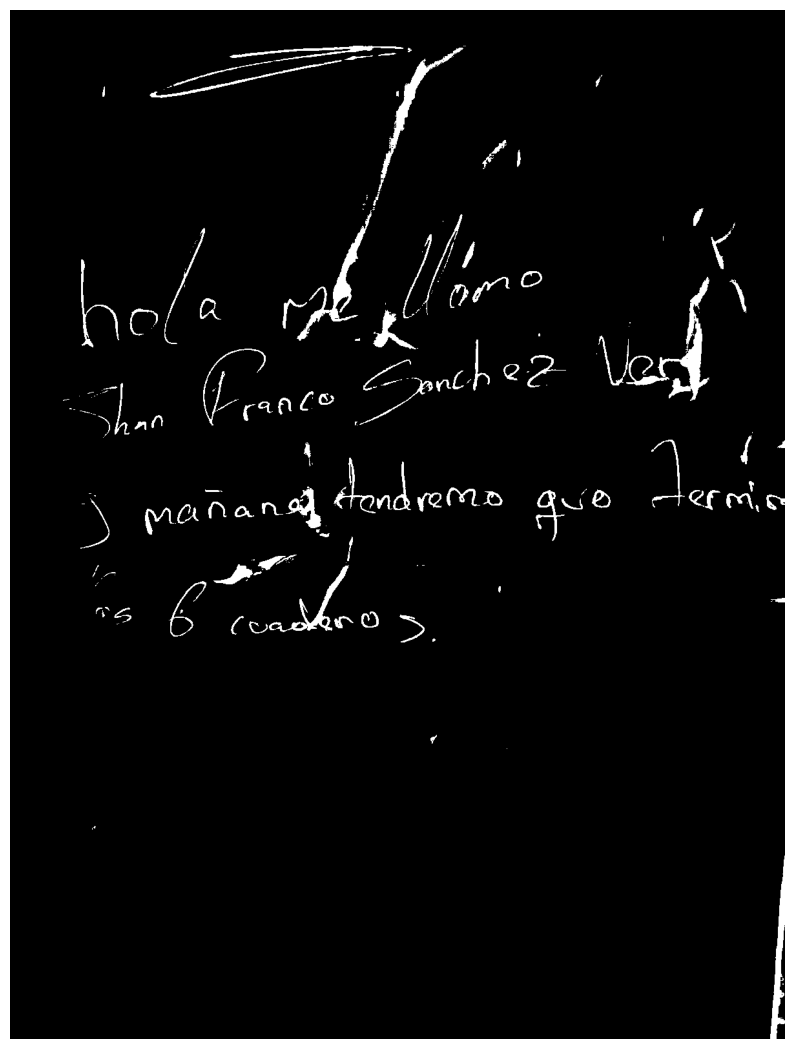

In [19]:
plt.figure(figsize=(10, 18))
plt.imshow(grupos_imagen, cmap="gray")
plt.axis("off")
plt.show()

In [20]:
binaria_km = np.where(grupos_imagen == gr_tinta, 255, 0).astype(np.uint8)

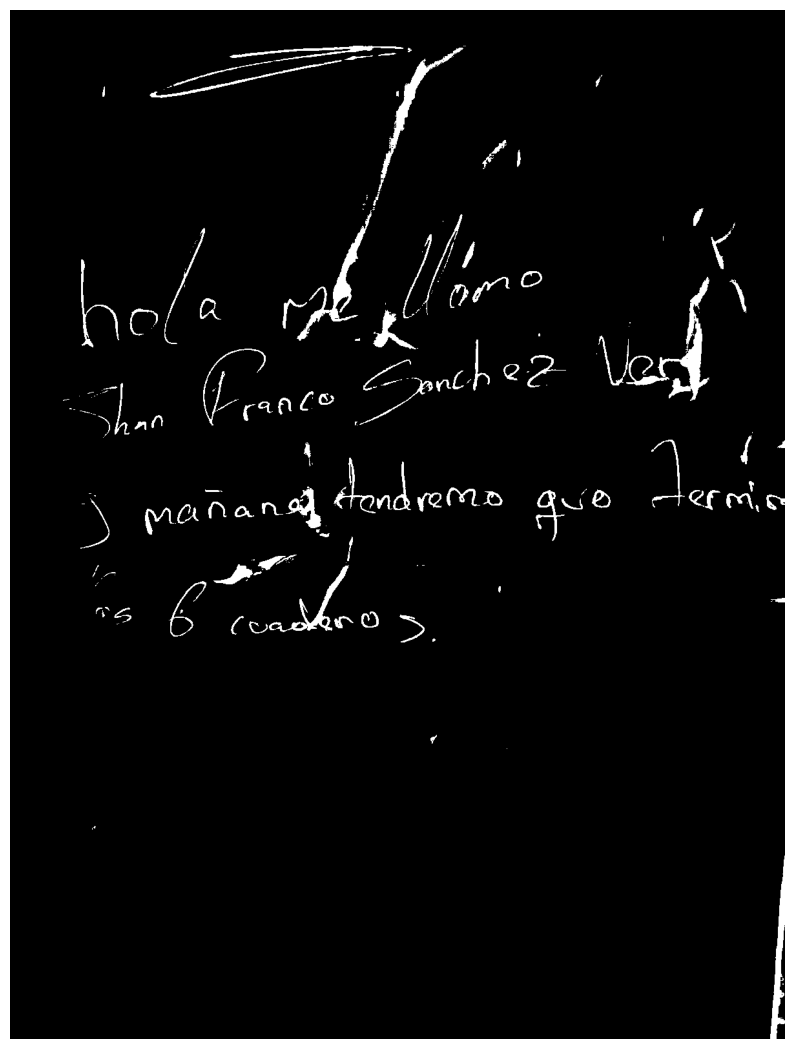

In [21]:
plt.figure(figsize=(10,18))
plt.imshow(binaria_km, cmap="gray")
plt.axis("off")
plt.show()

### binarizar con Otsu y comparar con K-Means

In [22]:
_, binaria_otsu = cv2.threshold(gris_parejo, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

p("% de tinta con K-Means:", round((binaria_km > 0).mean() * 100, 2))
p("% de tinta con Otsu:", round((binaria_otsu > 0).mean() * 100, 2))

% de tinta con K-Means: 2.23
% de tinta con Otsu: 2.75


### comparar el umbral de Otsu con el de K-Means

In [23]:
umbral_otsu = cv2.threshold(gris_parejo, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[0]
umbral_km = (centros[0] + centros[1]) / 2

p("Umbral de Otsu:", umbral_otsu)
p("Umbral de K-Means:", round(umbral_km, 2))

Umbral de Otsu: 225.0
Umbral de K-Means: 221.94


### veamos en imagen

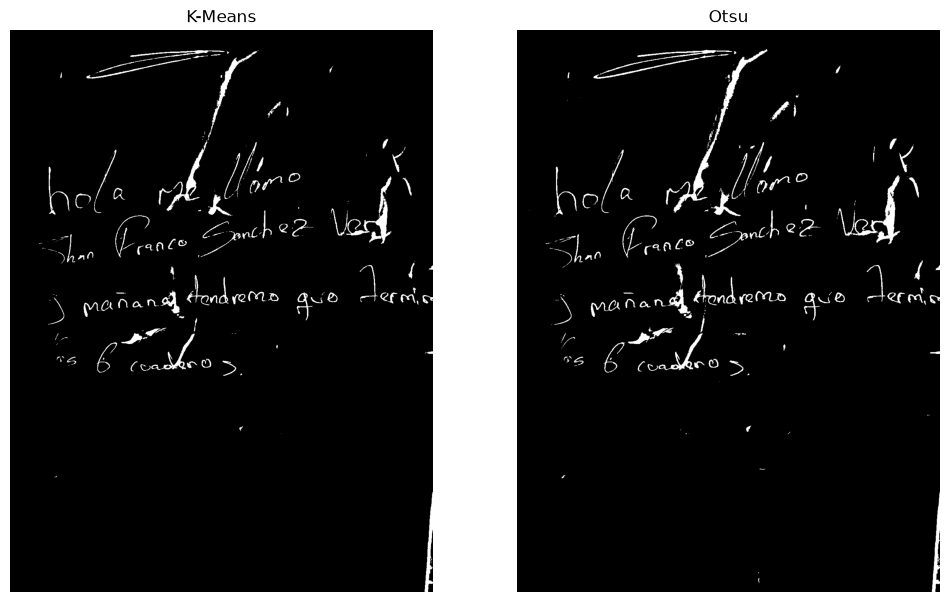

In [24]:
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.imshow(binaria_km, cmap="gray")
plt.title("K-Means")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(binaria_otsu, cmap="gray")
plt.title("Otsu")
plt.axis("off")
plt.show()

### borrar lo que toca el borde

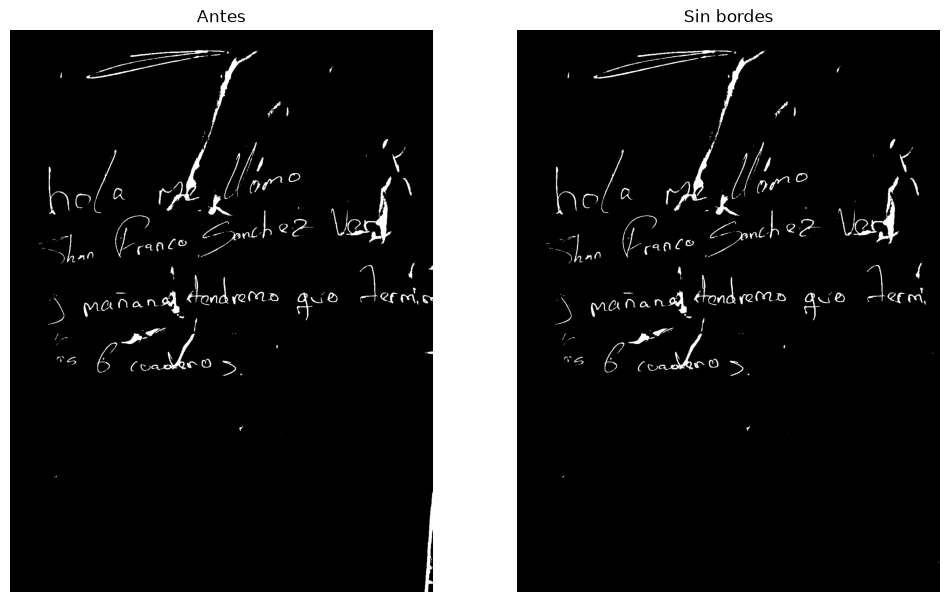

In [25]:
sin_bordes = binaria_km.copy()

cantidad, mapa, estadisticas, centros_piezas = cv2.connectedComponentsWithStats(sin_bordes, connectivity=8)
alto_imagen, ancho_imagen = sin_bordes.shape

for i in range(1, cantidad):
    x, y, ancho_pieza, alto_pieza, area = estadisticas[i]
    if x == 0 or y == 0 or x + ancho_pieza == ancho_imagen or y + alto_pieza == alto_imagen:
        sin_bordes[mapa == i] = 0

plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
plt.imshow(binaria_km, cmap="gray")
plt.title("Antes")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(sin_bordes, cmap="gray")
plt.title("Sin bordes")
plt.axis("off")
plt.show()

### seleccionar las piezas que pueden ser letras

Piezas en total: 224
Piezas que pueden ser letras: 99


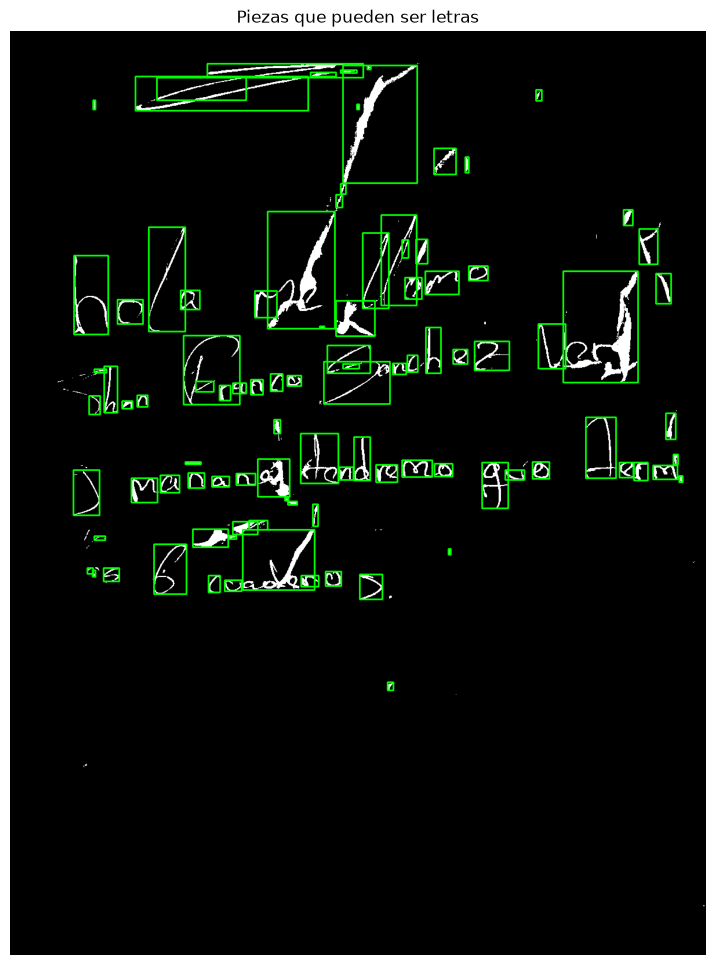

In [26]:
cantidad, mapa, estadisticas, centros_piezas = cv2.connectedComponentsWithStats(sin_bordes, connectivity=8)

cajas = []
for i in range(1, cantidad):
    x, y, ancho_pieza, alto_pieza, area = estadisticas[i]
    if area >= 20:
        cajas.append((x, y, ancho_pieza, alto_pieza))

p("Piezas en total:", cantidad - 1)
p("Piezas que pueden ser letras:", len(cajas))

marcada = cv2.cvtColor(sin_bordes, cv2.COLOR_GRAY2RGB)
for x, y, ancho_pieza, alto_pieza in cajas:
    cv2.rectangle(marcada, (x, y), (x + ancho_pieza, y + alto_pieza), (0, 255, 0), 2)

plt.figure(figsize=(10, 12))
plt.imshow(marcada)
plt.title("Piezas que pueden ser letras")
plt.axis("off")
plt.show()

In [27]:
altura_normal = float(np.median([alto_pieza for x, y, ancho_pieza, alto_pieza in cajas]))
p("Alto normal de una letra:", altura_normal, "píxeles")

Alto normal de una letra: 27.0 píxeles


### juntar las piezas por renglón

In [29]:
renglones = []

for caja in sorted(cajas, key=lambda c: c[1] + c[3] / 2):
    centro_y = caja[1] + caja[3] / 2
    if renglones and abs(centro_y - renglones[-1]["centro"]) < 0.7 * altura_normal:
        renglones[-1]["cajas"].append(caja)
        renglones[-1]["centro"] = float(np.mean([c[1] + c[3] / 2 for c in renglones[-1]["cajas"]]))
    else:
        renglones.append({"centro": centro_y, "cajas": [caja]})

p("Renglones encontrados:", len(renglones))
for numero, renglon in enumerate(renglones):
    p("Renglón", numero, ":", len(renglon["cajas"]), "piezas, a la altura", round(renglon["centro"]))

Renglones encontrados: 25
Renglón 0 : 4 piezas, a la altura 69
Renglón 1 : 3 piezas, a la altura 106
Renglón 2 : 2 piezas, a la altura 129
Renglón 3 : 1 piezas, a la altura 160
Renglón 4 : 2 piezas, a la altura 228
Renglón 5 : 1 piezas, a la altura 272
Renglón 6 : 1 piezas, a la altura 293
Renglón 7 : 1 piezas, a la altura 322
Renglón 8 : 3 piezas, a la altura 376
Renglón 9 : 5 piezas, a la altura 413
Renglón 10 : 4 piezas, a la altura 444
Renglón 11 : 3 piezas, a la altura 473
Renglón 12 : 3 piezas, a la altura 506
Renglón 13 : 7 piezas, a la altura 562
Renglón 14 : 10 piezas, a la altura 603
Renglón 15 : 4 piezas, a la altura 638
Renglón 16 : 2 piezas, a la altura 682
Renglón 17 : 5 piezas, a la altura 735
Renglón 18 : 16 piezas, a la altura 767
Renglón 19 : 4 piezas, a la altura 802
Renglón 20 : 3 piezas, a la altura 848
Renglón 21 : 3 piezas, a la altura 874
Renglón 22 : 2 piezas, a la altura 905
Renglón 23 : 9 piezas, a la altura 944
Renglón 24 : 1 piezas, a la altura 1130


### este método no separó bien los renglones, así que se prueba otro

### separar renglones y palabras según el espacio entre las letras

In [30]:
renglones = []
margen = 0.5 * altura_normal

for caja in sorted(cajas, key=lambda c: c[1]):
    x, y, ancho_pieza, alto_pieza = caja
    if renglones and y <= renglones[-1]["abajo"] + margen:
        renglones[-1]["cajas"].append(caja)
        renglones[-1]["abajo"] = max(renglones[-1]["abajo"], y + alto_pieza)
    else:
        renglones.append({"arriba": y, "abajo": y + alto_pieza, "cajas": [caja]})

p("Renglones encontrados:", len(renglones))
for numero, renglon in enumerate(renglones):
    p("Renglón", numero, ":", len(renglon["cajas"]), "piezas, desde", renglon["arriba"], "hasta", renglon["abajo"])

Renglones encontrados: 2
Renglón 0 : 98 piezas, desde 56 hasta 980
Renglón 1 : 1 piezas, desde 1123 hasta 1137


In [32]:
for numero, renglon in enumerate(renglones):
    renglon["cajas"] = sorted(renglon["cajas"], key=lambda c: c[0])
    p("Renglón", numero, ":", renglon["cajas"][:5])

Renglón 0 : [(np.int32(109), np.int32(757), np.int32(45), np.int32(78)), (np.int32(110), np.int32(387), np.int32(59), np.int32(136)), (np.int32(133), np.int32(926), np.int32(10), np.int32(10)), (np.int32(136), np.int32(629), np.int32(19), np.int32(32)), (np.int32(142), np.int32(930), np.int32(5), np.int32(11))]
Renglón 1 : [(np.int32(651), np.int32(1123), np.int32(10), np.int32(14))]


In [33]:
umbral_espacio = 0.5 * altura_normal

for numero, renglon in enumerate(renglones):
    letras = renglon["cajas"]
    palabras = []
    palabra_actual = []

    for i in range(len(letras)):
        letra = letras[i]
        palabra_actual.append(letra)

        es_la_ultima = i == len(letras) - 1

        if es_la_ultima:
            palabras.append(palabra_actual)
        else:
            siguiente = letras[i + 1]
            fin_de_letra = letra[0] + letra[2]
            distancia = siguiente[0] - fin_de_letra

            if distancia > umbral_espacio:
                palabras.append(palabra_actual)
                palabra_actual = []

    renglon["palabras"] = palabras
    p("Renglón", numero, ":", len(palabras), "palabras")

Renglón 0 : 2 palabras
Renglón 1 : 1 palabras


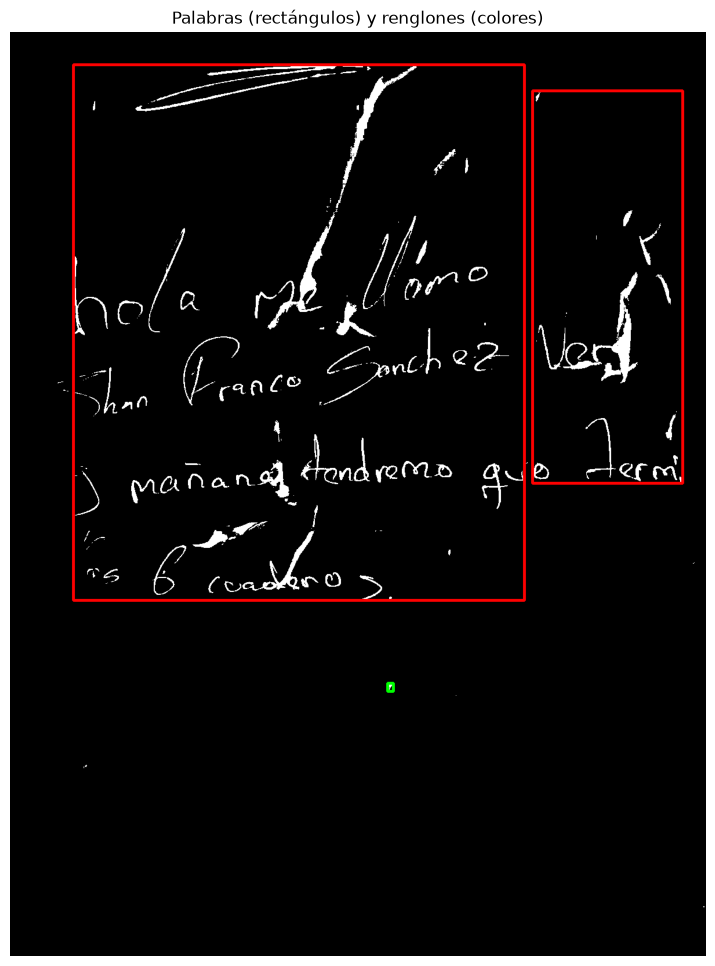

In [36]:
marcada = cv2.cvtColor(sin_bordes, cv2.COLOR_GRAY2RGB)
colores = [(255, 0, 0), (0, 255, 0), (0, 128, 255), (255, 200, 0)]

for numero, renglon in enumerate(renglones):
    color = colores[numero % 4]

    for palabra in renglon["palabras"]:
        x_min, y_min = 10000, 10000
        x_max, y_max = 0, 0

        for x, y, ancho_pieza, alto_pieza in palabra:
            x_min = min(x_min, x)
            y_min = min(y_min, y)
            x_max = max(x_max, x + ancho_pieza)
            y_max = max(y_max, y + alto_pieza)

        cv2.rectangle(marcada, (x_min, y_min), (x_max, y_max), color, 3)

plt.figure(figsize=(10, 12))
plt.imshow(marcada)
plt.title("Palabras (rectángulos) y renglones (colores)")
plt.axis("off")
plt.show()

Tamaño del recorte: (136, 59)


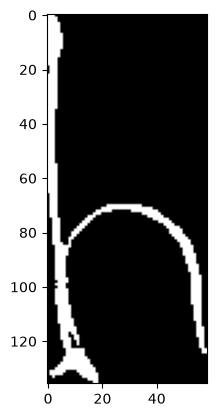

In [37]:
x, y, ancho_pieza, alto_pieza = renglones[0]["palabras"][0][1]
recorte = sin_bordes[y:y + alto_pieza, x:x + ancho_pieza]

p("Tamaño del recorte:", recorte.shape)
plt.imshow(recorte, cmap="gray")
plt.show()

Tamaño: (28, 28)


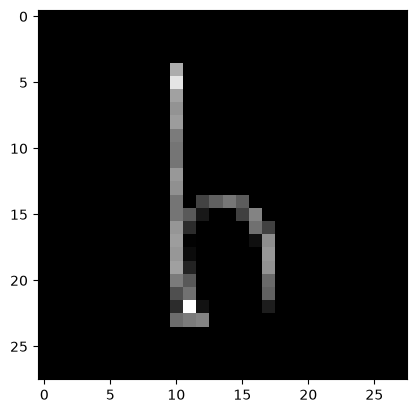

In [38]:
alto_r, ancho_r = recorte.shape
escala = 20 / max(alto_r, ancho_r)
nuevo_ancho_r = int(ancho_r * escala)
nuevo_alto_r = int(alto_r * escala)
chico = cv2.resize(recorte, (nuevo_ancho_r, nuevo_alto_r), interpolation=cv2.INTER_AREA)

letra_28 = np.zeros((28, 28), np.uint8)
arriba = (28 - nuevo_alto_r) // 2
izquierda = (28 - nuevo_ancho_r) // 2
letra_28[arriba:arriba + nuevo_alto_r, izquierda:izquierda + nuevo_ancho_r] = chico

p("Tamaño:", letra_28.shape)
plt.imshow(letra_28, cmap="gray")
plt.show()


Letras recortadas: 99


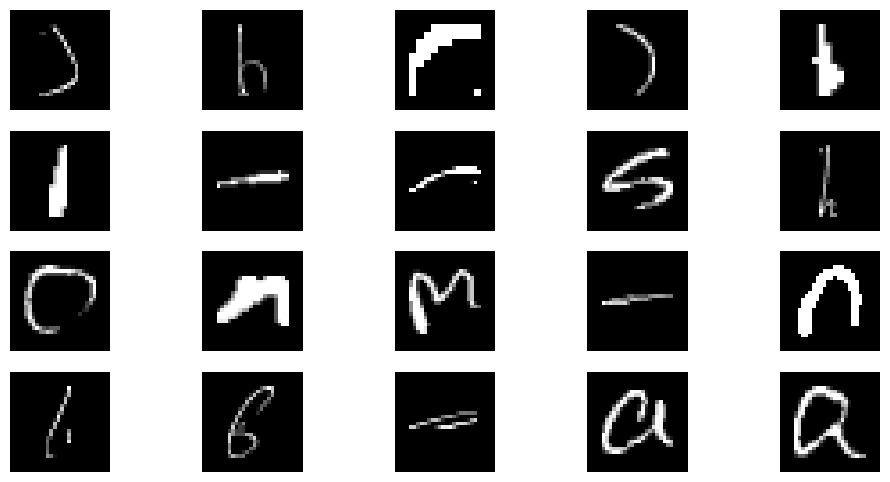

In [41]:
letras_28 = []

for renglon in renglones:
    for palabra in renglon["palabras"]:
        for x, y, ancho_pieza, alto_pieza in palabra:
            recorte = sin_bordes[y:y + alto_pieza, x:x + ancho_pieza]

            alto_r, ancho_r = recorte.shape
            escala = 20 / max(alto_r, ancho_r)
            nuevo_ancho_r = max(1, int(ancho_r * escala))
            nuevo_alto_r = max(1, int(alto_r * escala))
            chico = cv2.resize(recorte, (nuevo_ancho_r, nuevo_alto_r), interpolation=cv2.INTER_AREA)

            letra_28 = np.zeros((28, 28), np.uint8)
            arriba = (28 - nuevo_alto_r) // 2
            izquierda = (28 - nuevo_ancho_r) // 2
            letra_28[arriba:arriba + nuevo_alto_r, izquierda:izquierda + nuevo_ancho_r] = chico

            letras_28.append(letra_28)

p("Letras recortadas:", len(letras_28))

plt.figure(figsize=(12, 6))
for i in range(20):
    plt.subplot(4, 5, i + 1)
    plt.imshow(letras_28[i], cmap="gray")
    plt.axis("off")
plt.show()

In [45]:
Carpeta_src = Carpeta_Proyecto / "src"
Carpeta_src.mkdir(parents=True, exist_ok=True)
p("Carpeta src:", Carpeta_src)

Carpeta src: /home/Ian/prediccion_red/src


### Función para limpiar la imagen

In [46]:
%%writefile ../src/procesamiento.py
import cv2
import numpy as np
from sklearn.cluster import KMeans


def limpiar_foto(foto):
    alto, ancho = foto.shape[:2]
    nuevo_ancho = 1200
    nuevo_alto = int(alto * nuevo_ancho / ancho)
    foto_scala = cv2.resize(foto, (nuevo_ancho, nuevo_alto), interpolation=cv2.INTER_AREA)
    gris = cv2.cvtColor(foto_scala, cv2.COLOR_BGR2GRAY)

    nucleo = np.ones((15, 15), np.uint8)
    fondo = cv2.medianBlur(cv2.dilate(gris, nucleo), 31)
    gris_parejo = cv2.divide(gris, fondo, scale=255)

    puntos = gris_parejo.reshape(-1, 1).astype(np.float32)
    generador = np.random.default_rng(42)
    muestra = puntos[generador.choice(len(puntos), 20000, replace=False)]
    km = KMeans(n_clusters=2, random_state=42, n_init=10)
    km.fit(muestra)
    grupos = km.predict(puntos)

    centros = km.cluster_centers_.ravel()
    gr_tinta = np.argmin(centros)
    grupos_imagen = grupos.reshape(gris_parejo.shape)
    binaria_km = np.where(grupos_imagen == gr_tinta, 255, 0).astype(np.uint8)

    sin_bordes = binaria_km.copy()
    cantidad, mapa, estadisticas, centros_piezas = cv2.connectedComponentsWithStats(sin_bordes, connectivity=8)
    alto_imagen, ancho_imagen = sin_bordes.shape
    for i in range(1, cantidad):
        x, y, ancho_pieza, alto_pieza, area = estadisticas[i]
        if x == 0 or y == 0 or x + ancho_pieza == ancho_imagen or y + alto_pieza == alto_imagen:
            sin_bordes[mapa == i] = 0

    return sin_bordes

Overwriting ../src/procesamiento.py


### Función para sacar las letras 

In [1]:
%%writefile -a ../src/procesamiento.py


def sacar_letras(sin_bordes):
    cantidad, mapa, estadisticas, centros_piezas = cv2.connectedComponentsWithStats(sin_bordes, connectivity=8)
    cajas = []
    for i in range(1, cantidad):
        x, y, ancho_pieza, alto_pieza, area = estadisticas[i]
        if area >= 20:
            cajas.append((x, y, ancho_pieza, alto_pieza))

    altura_normal = float(np.median([alto_pieza for x, y, ancho_pieza, alto_pieza in cajas]))

    renglones = []
    margen = 0.5 * altura_normal
    for caja in sorted(cajas, key=lambda c: c[1]):
        x, y, ancho_pieza, alto_pieza = caja
        if renglones and y <= renglones[-1]["abajo"] + margen:
            renglones[-1]["cajas"].append(caja)
            renglones[-1]["abajo"] = max(renglones[-1]["abajo"], y + alto_pieza)
        else:
            renglones.append({"arriba": y, "abajo": y + alto_pieza, "cajas": [caja]})

    umbral_espacio = 0.5 * altura_normal
    for renglon in renglones:
        letras = sorted(renglon["cajas"], key=lambda c: c[0])
        palabras = []
        palabra_actual = []
        for i in range(len(letras)):
            letra = letras[i]
            palabra_actual.append(letra)
            if i == len(letras) - 1:
                palabras.append(palabra_actual)
            else:
                siguiente = letras[i + 1]
                distancia = siguiente[0] - (letra[0] + letra[2])
                if distancia > umbral_espacio:
                    palabras.append(palabra_actual)
                    palabra_actual = []
        renglon["palabras"] = palabras

    texto_letras = []
    for renglon in renglones:
        linea = []
        for palabra in renglon["palabras"]:
            palabra_28 = []
            for x, y, ancho_pieza, alto_pieza in palabra:
                recorte = sin_bordes[y:y + alto_pieza, x:x + ancho_pieza]
                alto_r, ancho_r = recorte.shape
                escala = 20 / max(alto_r, ancho_r)
                nuevo_ancho_r = max(1, int(ancho_r * escala))
                nuevo_alto_r = max(1, int(alto_r * escala))
                chico = cv2.resize(recorte, (nuevo_ancho_r, nuevo_alto_r), interpolation=cv2.INTER_AREA)
                letra_28 = np.zeros((28, 28), np.uint8)
                arriba = (28 - nuevo_alto_r) // 2
                izquierda = (28 - nuevo_ancho_r) // 2
                letra_28[arriba:arriba + nuevo_alto_r, izquierda:izquierda + nuevo_ancho_r] = chico
                palabra_28.append(letra_28)
            linea.append(palabra_28)
        texto_letras.append(linea)

    return texto_letras

Appending to ../src/procesamiento.py
